# 01. 영상 데이터 다루기 기초 - 프레임 샘플링

Food101에서는 입력이 이미지 한 장(H, W, C)이었다. 영상은 여기에 **시간(T)** 축이 하나 더 붙는다.

영상 분류 모델(3D CNN)에 넣는 입력 단위는 보통 영상 전체가 아니라, 영상에서 일정 개수의 프레임을
뽑아 쌓은 **클립(clip)** 이다. 예를 들어 10초짜리 영상에서 16장만 균등한 간격으로 뽑아
`(T=16, H=112, W=112, C=3)` 텐서 하나로 만드는 식이다.

이 노트북에서는:
1. 학습에 쓸 작은 영상 데이터셋(UCF101의 일부 클래스)을 전체 다운로드 없이 필요한 파일만 받아오고
2. OpenCV로 영상을 열어 프레임 수 / FPS / 해상도 같은 기본 정보를 확인하고
3. 균등 샘플링으로 클립을 뽑아 그리드로 시각화해본다.


## 1-1. 왜 UCF101의 '일부'만 받는가

UCF101은 101개 동작 클래스, 총 13,320개 영상(약 6.5GB)으로 이루어진 표준 행동 인식 데이터셋이다.
지금 목표는 "영상 데이터를 다루고 파인튜닝해보는 방법"을 익히는 것이지 101개 클래스를 다 맞히는 게
아니므로, RTX 2060(6GB) 환경에 맞게 작은 서브셋만 받는다.

**업데이트**: 원래는 공식 TensorFlow 튜토리얼처럼 `remotezip`으로 구글 클라우드 스토리지
(`storage.googleapis.com/thumos14_files/...`)에서 원하는 클래스만 골라 받는 방식으로 짰었는데,
그 버킷이 프록시/방화벽 환경에 따라 막혀 있는 경우가 있어서(403) 더 안정적인 경로로 바꿨다:
같은 TensorFlow 튜토리얼 코드로 미리 만들어둔 **10개 클래스 서브셋(클래스당 50개, 총 500개 영상,
약 171MB)**을 Hugging Face에 올려둔 미러(`sayakpaul/ucf101-subset`)에서 압축파일 하나로 통째로
받는다. 일반 HTTPS GET 한 번이라 더 간단하고 잘 막히지 않는다.

(`remotezip`으로 직접 원하는 클래스를 고르는 원래 방식은 맨 아래에 참고용으로 남겨뒀다 — 저 구글
버킷이 네트워크에서 열리는 사람은 그 방식을 그대로 써도 된다.)

In [ ]:
# 필요한 패키지 설치 (최초 1회)
# %pip install opencv-python torch torchvision matplotlib tqdm requests


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
from video_utils import sample_frames_uniform  # 같은 폴더의 공용 유틸

DATA_ROOT = Path("data")
DATA_DIR = DATA_ROOT / "UCF101_subset"  # 최종적으로 train/val/test가 위치할 경로
TAR_URL = (
    "https://huggingface.co/datasets/sayakpaul/ucf101-subset/"
    "resolve/main/UCF101_subset.tar.gz"
)
TAR_PATH = DATA_ROOT / "UCF101_subset.tar.gz"


## 1-2. 다운로드 + 압축 해제

`requests`로 스트리밍 다운로드하면서 `tqdm`으로 진행률을 보여준다. 아카이브 내부에 중간 폴더가
하나 더 있을 수도 있어서(아카이브마다 조금씩 다르다), `train`/`val`/`test`가 모두 들어있는 폴더를
직접 찾아서 `DATA_DIR`로 정리해준다 — 이렇게 하면 뒤 노트북들은 아카이브 내부 구조가 어떻든
항상 `data/UCF101_subset/{train,val,test}/<클래스>/*.avi` 경로만 보면 된다.

In [2]:
import shutil
import tarfile

import requests
from tqdm.auto import tqdm


def find_split_root(root: Path) -> Path:
    """압축을 푼 폴더 아래에서 train/val/test를 모두 가진 디렉터리를 찾는다."""
    for p in root.rglob("train"):
        if p.is_dir() and (p.parent / "val").is_dir() and (p.parent / "test").is_dir():
            return p.parent
    raise RuntimeError(f"{root} 아래에서 train/val/test 폴더를 찾지 못했습니다.")


if DATA_DIR.exists():
    print(f"{DATA_DIR} 이미 존재함 - 다운로드 생략")
else:
    DATA_ROOT.mkdir(exist_ok=True)

    if not TAR_PATH.exists():
        with requests.get(TAR_URL, stream=True, timeout=30) as r:
            r.raise_for_status()
            total = int(r.headers.get("content-length", 0))
            with open(TAR_PATH, "wb") as f, tqdm(
                total=total, unit="B", unit_scale=True, desc="다운로드"
            ) as pbar:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
                    pbar.update(len(chunk))

    extract_tmp = DATA_ROOT / "_extract_tmp"
    shutil.rmtree(extract_tmp, ignore_errors=True)
    extract_tmp.mkdir()
    with tarfile.open(TAR_PATH) as tf:
        tf.extractall(extract_tmp, filter="data")

    split_root = find_split_root(extract_tmp)
    split_root.rename(DATA_DIR)
    shutil.rmtree(extract_tmp, ignore_errors=True)
    print(f"압축 해제 완료 -> {DATA_DIR}")


/home/noni/Documents/knowledge/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
다운로드: 100%|██████████| 171M/171M [00:03<00:00, 51.3MB/s] 


압축 해제 완료 -> data/UCF101_subset


## 1-3. 클래스 확인

클래스 이름을 하드코딩하지 않고, 받아진 폴더 구조에서 그대로 읽어온다 — 이렇게 하면 어떤 서브셋을
받든(10개든, 나중에 더 많은 클래스로 바꾸든) 노트북 코드를 고칠 필요가 없다.

In [3]:
CLASSES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
print(f"클래스 {len(CLASSES)}개:", CLASSES)

for split in ["train", "val", "test"]:
    for cls in CLASSES:
        n = len(list((DATA_DIR / split / cls).glob("*.avi")))
        print(f"{split:>5} / {cls:<18}: {n}개")


클래스 10개: ['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam', 'BandMarching', 'BaseballPitch', 'Basketball', 'BasketballDunk', 'BenchPress']
train / ApplyEyeMakeup    : 30개
train / ApplyLipstick     : 30개
train / Archery           : 30개
train / BabyCrawling      : 30개
train / BalanceBeam       : 30개
train / BandMarching      : 30개
train / BaseballPitch     : 30개
train / Basketball        : 30개
train / BasketballDunk    : 30개
train / BenchPress        : 30개
  val / ApplyEyeMakeup    : 3개
  val / ApplyLipstick     : 3개
  val / Archery           : 3개
  val / BabyCrawling      : 3개
  val / BalanceBeam       : 3개
  val / BandMarching      : 3개
  val / BaseballPitch     : 3개
  val / Basketball        : 3개
  val / BasketballDunk    : 3개
  val / BenchPress        : 3개
 test / ApplyEyeMakeup    : 6개
 test / ApplyLipstick     : 4개
 test / Archery           : 7개
 test / BabyCrawling      : 9개
 test / BalanceBeam       : 4개
 test / BandMarching      : 9개
 test / BaseballPi

### (참고) 원하는 클래스만 직접 고르고 싶다면

아래는 `remotezip`으로 구글 클라우드 스토리지의 공식 UCF101 zip에서 원하는 클래스만 골라 받는
코드다. 환경에서 `storage.googleapis.com`이 막혀 있지 않다면 이 방식도 잘 동작하고,
`CuttingInKitchen`, `Mixing`, `PizzaTossing`처럼 요리 관련 클래스만 골라보는 것도 가능하다.
지금은 위 1-2에서 이미 데이터를 받았으니 실행할 필요는 없다 (실행하려면 주석을 해제).

In [ ]:
# %pip install remotezip
#
# from remotezip import RemoteZip
#
# ZIP_URL = "https://storage.googleapis.com/thumos14_files/UCF101_videos.zip"
# WANTED_CLASSES = ["CuttingInKitchen", "Mixing", "PizzaTossing", "ApplyEyeMakeup", "JugglingBalls"]
# FILES_PER_CLASS = {"train": 12, "val": 4, "test": 4}
#
# with RemoteZip(ZIP_URL) as zf:
#     all_files = [f for f in zf.namelist() if f.endswith(".avi")]
#
# def get_class_name(filename: str) -> str:
#     # 'UCF101/v_CuttingInKitchen_g01_c01.avi' -> 'CuttingInKitchen'
#     return filename.split("/")[-1].split("_")[1]
#
# files_by_class = defaultdict(list)
# for f in all_files:
#     files_by_class[get_class_name(f)].append(f)
#
# manual_data_dir = Path("data/UCF101_subset_manual")
# with RemoteZip(ZIP_URL) as zf:
#     for cls in WANTED_CLASSES:
#         cls_files = files_by_class[cls]
#         cursor = 0
#         for split, n in FILES_PER_CLASS.items():
#             split_dir = manual_data_dir / split / cls
#             split_dir.mkdir(parents=True, exist_ok=True)
#             for name in cls_files[cursor : cursor + n]:
#                 zf.extract(name, path=manual_data_dir)  # UCF101/xxx.avi 형태로 풀림
#                 extracted = manual_data_dir / name
#                 extracted.rename(split_dir / extracted.name)
#             cursor += n
# shutil.rmtree(manual_data_dir / "UCF101", ignore_errors=True)


## 1-4. 영상 기본 정보 확인

Food101에서 `image.size`를 확인했던 것처럼, 영상도 프레임 수 / FPS / 해상도를 먼저 확인한다.

In [5]:
import cv2

sample_path = next((DATA_DIR / "train" / CLASSES[0]).glob("*.avi"))
cap = cv2.VideoCapture(str(sample_path))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"{sample_path.name}")
print(f"프레임 수: {n_frames}, FPS: {fps:.1f}, 해상도: {w}x{h}, 길이: {n_frames/fps:.1f}초")


v_ApplyEyeMakeup_g19_c02.avi
프레임 수: 243, FPS: 25.0, 해상도: 320x240, 길이: 9.7초


## 1-5. 균등 샘플링으로 클립 뽑아서 시각화

`video_utils.sample_frames_uniform`이 영상 전체 길이에서 `num_frames`장을 균등 간격으로
뽑아준다. 영상마다 길이가 다르더라도 항상 고정된 프레임 수의 클립을 얻을 수 있다.

클립 shape: (16, 112, 112, 3) uint8


/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 47553 (\N{HANGUL SYLLABLE RING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 46108 (\N{HANGUL SYLLABLE DOEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_10326/1302855820.py:12: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.

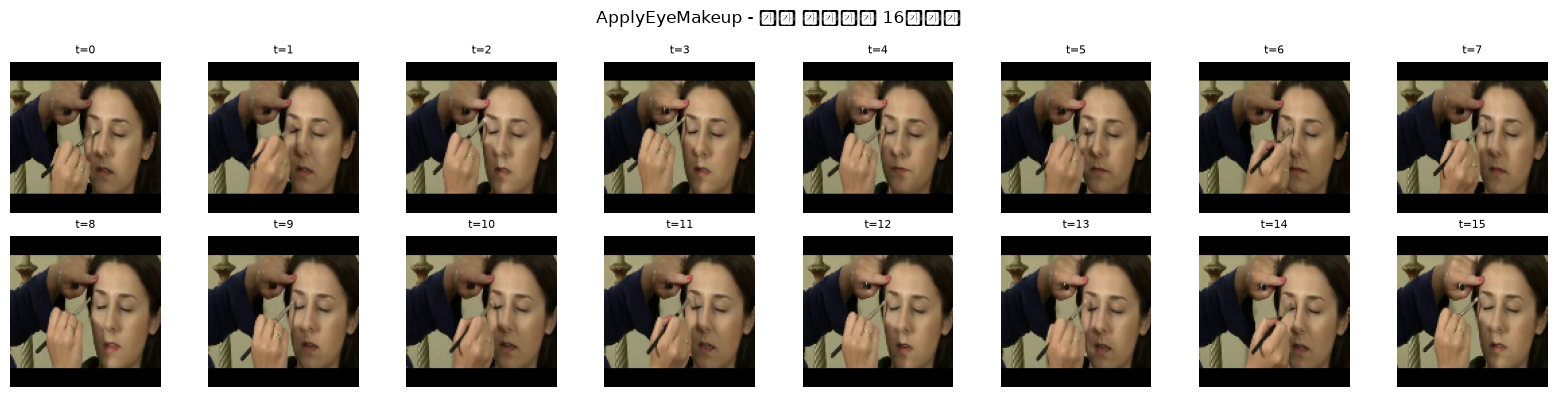

In [6]:
import matplotlib.pyplot as plt

clip = sample_frames_uniform(sample_path, num_frames=16, size=112)
print("클립 shape:", clip.shape, clip.dtype)  # (T, H, W, C)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(clip[i])
    ax.set_title(f"t={i}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"{sample_path.parent.name} - 균등 샘플링된 16프레임")
plt.tight_layout()
plt.show()


다음 노트북(`02_pytorch_video_dataset.ipynb`)에서는 이 샘플링 함수를 PyTorch `Dataset`으로
감싸서 `DataLoader`로 배치 단위로 불러오는 것까지 해본다.